# 02 Embedding-space geometry and hubness

Self-contained: this notebook downloads NFCorpus from the Hugging Face Hub, embeds it, and computes every number and figure from scratch. It does not read `results/`, `cache/`, or any `silent_rag` module, so it runs on a fresh machine with only the pip packages below. Expect roughly 10-20 minutes on a laptop CPU (embedding ~3.6k documents plus the t-SNE runs).

**Questions**
1. How do queries and documents sit in the space?
2. Are the t-SNE pictures trustworthy?
3. Is hubness more than high-dimensional geometry?

**Approach**
PCA variance, query-document cosines, t-SNE trustworthiness across seeds and perplexity, and hubness on equal-size subsamples against isotropic and covariance-matched null vectors.

**Scope.** NFCorpus only, the project's development set. SciFact and FiQA are held out for the final run, so this notebook deliberately does not load them. Cross-dataset comparisons from the earlier version (query-document separation, hubness skew, hub-driver signs) are therefore not reproduced here.

In [1]:
# Uncomment on a fresh environment.
# %pip install -q datasets sentence-transformers scikit-learn scipy pandas numpy matplotlib

In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # macOS: OpenMP clash between libraries; harmless elsewhere
os.environ.setdefault("OMP_NUM_THREADS", "1")

import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from scipy import stats
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

SEED = 0
np.random.seed(SEED)
K = 10  # top-k used for k-occurrence
SPLITS = ["train", "validation", "test"]

# NFCorpus, pinned to Hub revisions so the numbers are reproducible.
NFCORPUS = dict(
    repo="BeIR/nfcorpus", revision="b5026a0e96e8a7ac4f95f482a596389289d46269",
    qrels="BeIR/nfcorpus-qrels", qrels_revision="a451b3b26d3ae1358f259c1a3a4dd61fcea35a65",
)
MODEL = dict(repo="sentence-transformers/multi-qa-MiniLM-L6-cos-v1", revision="b207367332321f8e44f96e224ef15bc607f4dbf0")
MAX_SEQ = 512

N_PROJ_DOCS = 3000    # documents sampled for PCA / t-SNE picture
N_RANDOM_DOCS = 1000  # random documents per query for the cosine baseline
N_TRUST = 2000        # queries used for the trustworthiness study

/Users/Shared/github_shared/Silent-RAG-Failures/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1016 00:47:36.944000 57075 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Helpers and data

Data loading, encoding and the retrieval needed for k-occurrence are defined here. Every labelled query from the train, validation and test qrels is used, and a query keeps the first split it appears in.

In [3]:
def doc_text(title, text):
    return f"{(title or '').strip()} {(text or '').strip()}".strip()


def load_nfcorpus():
    c = NFCORPUS
    corpus = load_dataset(c["repo"], "corpus", split="corpus", revision=c["revision"])
    queries = load_dataset(c["repo"], "queries", split="queries", revision=c["revision"])
    qtext = {str(q["_id"]): q["text"] for q in queries}
    split_of, qrels = {}, {}
    for split in SPLITS:
        for row in load_dataset(c["qrels"], split=split, revision=c["qrels_revision"]):
            q = str(row["query-id"])
            if split_of.setdefault(q, split) == split:
                qrels.setdefault(q, {})[str(row["corpus-id"])] = int(row["score"])
    doc_ids = [str(d["_id"]) for d in corpus]
    docs = [doc_text(t, x) for t, x in zip(corpus["title"], corpus["text"])]
    return doc_ids, docs, {q: qtext[q] for q in qrels}, qrels, split_of


def encode(enc, texts, batch_size=32):
    return np.ascontiguousarray(enc.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                                           convert_to_numpy=True, show_progress_bar=False), dtype=np.float32)


def unit(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)


doc_ids, docs, queries, qrels, split_of = load_nfcorpus()
enc = SentenceTransformer(MODEL["repo"], revision=MODEL["revision"], device="cpu")
enc.max_seq_length = MAX_SEQ

# Only queries with at least one relevant document are kept, as in the benchmark.
qids = [q for q in queries if any(r > 0 for r in qrels[q].values())]
D = encode(enc, docs)
Q = encode(enc, [queries[q] for q in qids])
sp = np.array([split_of[q] for q in qids])
rel = [{d for d, v in qrels[q].items() if v > 0} for q in qids]
print(f"{len(docs)} docs, {len(qids)} queries", {s: int((sp == s).sum()) for s in SPLITS}, "embedding dim", D.shape[1])

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19130.02it/s]


3633 docs, 3237 queries {'train': 2590, 'validation': 324, 'test': 323} embedding dim 384


## Query-document separation

For each query, the mean cosine to its relevant documents against the mean cosine to 1,000 random documents. The gap says how far relevant documents sit from the query beyond what any document does. Also the nearest-neighbour cosine from each query to the other queries and from each document to the other documents (all documents; a subsample would lower it because each document has fewer candidates), which shows how tightly each side clusters.

**Why this test**
- **Estimand:** mean over queries of (mean cosine to judged-relevant documents minus mean cosine to random documents). Descriptive: no test is run, because the gap is large relative to its spread and no decision depends on rejecting zero.
- **Unit of independence:** the query (with ~41 judged-relevant documents per query, including level-1 indirect links, so the mean dilutes the best match).
- **Assumptions:** none; this is a summary of the geometry.
- **Why not the obvious alternative:** a paired test of relevant vs random cosine would reject trivially at n = 3,237 and add nothing.
- **Resolution / Monte-Carlo error:** 1,000 random documents per query; the random-document mean is accurate to about ±0.003 per query.

,queries_with_relevant,cos_query_relevant,cos_query_random,gap,nn_query_query_median,nn_doc_doc_median
0,3237,0.2,0.09,0.11,0.702,0.712


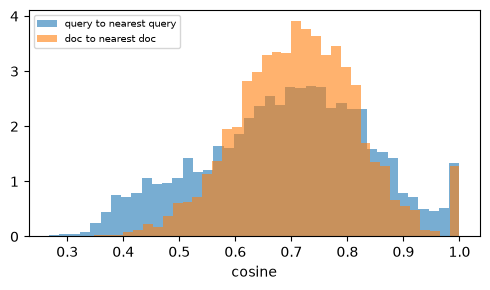

In [4]:
def nn_sim(A, B=None, chunk=1000):
    """Max cosine from each row of A to B (or to the other rows of A). Vectors are unit length."""
    self_ref = B is None
    B = A if self_ref else B
    best = np.empty(len(A), dtype=np.float32)
    for i in range(0, len(A), chunk):
        S = A[i : i + chunk] @ B.T
        if self_ref:
            S[np.arange(len(S)), np.arange(i, i + len(S))] = -np.inf
        best[i : i + chunk] = S.max(axis=1)
    return best


rng = np.random.default_rng(SEED)
pos = {d: i for i, d in enumerate(doc_ids)}
rel_cos, rand_cos = [], []
for qi, r in enumerate(rel):
    idx = [pos[d] for d in r if d in pos]
    rel_cos.append(float((D[idx] @ Q[qi]).mean()))
    rand_cos.append(float((D[rng.choice(len(D), N_RANDOM_DOCS, replace=False)] @ Q[qi]).mean()))
rel_cos, rand_cos = np.array(rel_cos), np.array(rand_cos)

qq = nn_sim(Q)
dd = nn_sim(D)   # whole corpus: a subsample lowers the nearest-neighbour similarity
display(pd.DataFrame([{"queries_with_relevant": len(rel_cos), "cos_query_relevant": rel_cos.mean(), "cos_query_random": rand_cos.mean(),
                       "gap": (rel_cos - rand_cos).mean(), "nn_query_query_median": np.median(qq), "nn_doc_doc_median": np.median(dd)}]).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(qq, bins=40, alpha=0.6, density=True, label="query to nearest query")
ax.hist(dd, bins=40, alpha=0.6, density=True, label="doc to nearest doc")
ax.set_xlabel("cosine")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## PCA variance

Cumulative variance explained by the first 100 principal components of the document embeddings. A steep curve would mean the space is effectively low-dimensional; a slow one means no 2D picture can capture much of it.

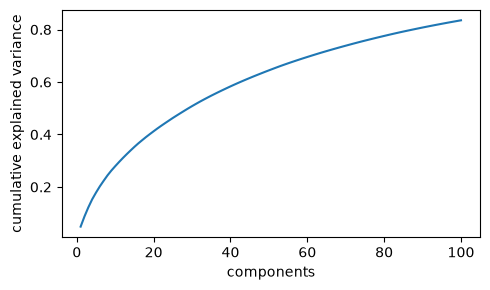

,var@2,var@10,var@50,var@100
0,0.088,0.279,0.644,0.835


In [5]:
pca_full = PCA(n_components=100, random_state=SEED).fit(D)
cum = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, len(cum) + 1), cum)
ax.set_xlabel("components")
ax.set_ylabel("cumulative explained variance")
fig.tight_layout()
plt.show()
pd.DataFrame([{f"var@{n}": float(cum[n - 1]) for n in (2, 10, 50, 100)}]).round(3)

## The t-SNE picture

One illustrative map: 3,000 documents and all queries, PCA to 50 dimensions, then t-SNE (perplexity 30). Documents relevant to at least one query are black. Treat this as illustration only; the next section tests how far to trust it.

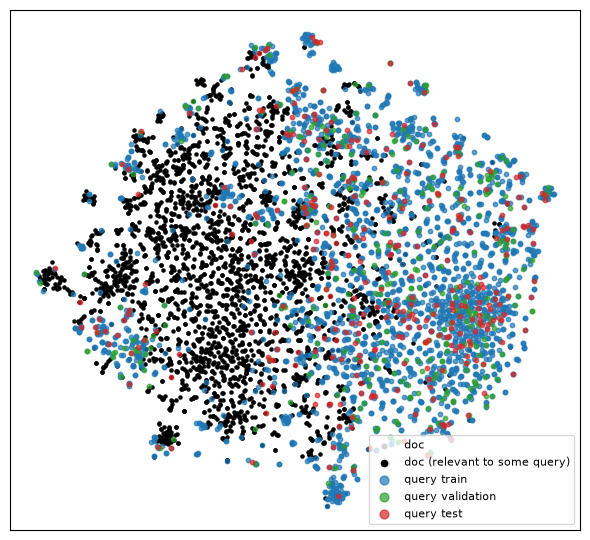

In [6]:
relevant_any = set().union(*rel)
rng = np.random.default_rng(SEED)
sample = rng.choice(len(D), N_PROJ_DOCS, replace=False)
X50 = PCA(n_components=50, random_state=SEED).fit_transform(np.vstack([D[sample], Q]))
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X50)
Zd, Zq = Z[: len(sample)], Z[len(sample):]
is_rel = np.array([doc_ids[i] in relevant_any for i in sample])

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(*Zd[~is_rel].T, s=3, c="lightgrey", label="doc")
ax.scatter(*Zd[is_rel].T, s=5, c="black", label="doc (relevant to some query)")
for s, c in {"train": "tab:blue", "validation": "tab:green", "test": "tab:red"}.items():
    ax.scatter(*Zq[sp == s].T, s=10, c=c, alpha=0.7, label=f"query {s}")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2, fontsize=8)
fig.tight_layout()
plt.show()

## t-SNE trustworthiness

Trustworthiness (0 to 1, `n_neighbors = 10`) is the share of 2D neighbours that were also neighbours in the original space, penalizing false neighbours. t-SNE runs on a 2,000-query subsample (after PCA to 50 dimensions) at three perplexities, with a plain 2D PCA as the baseline. With `init="pca"` the seed has no effect (the run is deterministic), so the **seed-to-seed spread** is measured with random initialization (three seeds), together with the Jaccard overlap of each point's 10 nearest neighbours between maps from different seeds. That overlap says how much of a picture is the algorithm, not the data.

**Why this test**
- **Estimand:** how faithfully a 2D map keeps each point's 10 nearest neighbours (trustworthiness), and how much the map changes with the random seed (neighbour overlap between seeds).
- **Unit of independence:** the t-SNE run (seed). Three seeds give only a rough spread.
- **Assumptions:** trustworthiness at k = 10 measures local structure only; it says nothing about distances between clusters.
- **Why not the obvious alternative:** judging a map by eye, or by trustworthiness alone, hides the seed dependence. The between-seed overlap is the quantity that says how much of a picture is reproducible. 2D PCA is a weak baseline, so beating it is a low bar.
- **Resolution / Monte-Carlo error:** 3 seeds per perplexity; the SD over seeds is a rough estimate.

In [7]:
def knn_sets(Z, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return [set(r) for r in idx]


def knn_overlap(Za, Zb):
    A, B_ = knn_sets(Za), knn_sets(Zb)
    return float(np.mean([len(a & b) / len(a | b) for a, b in zip(A, B_)]))


sub = np.random.default_rng(SEED).choice(len(Q), min(N_TRUST, len(Q)), replace=False)
X50q = PCA(50, random_state=SEED).fit_transform(Q[sub])
pca2 = PCA(2, random_state=SEED).fit_transform(Q[sub])

rows = [{"method": "PCA 2D", "init": "-", "perplexity": np.nan, "trust_mean": trustworthiness(Q[sub], pca2, n_neighbors=10),
         "trust_sd_over_seeds": np.nan, "knn_overlap_between_seeds": np.nan}]
for perp in (15, 30, 50):
    Zp = TSNE(2, perplexity=perp, init="pca", random_state=0).fit_transform(X50q)
    rows.append({"method": "t-SNE", "init": "pca", "perplexity": perp, "trust_mean": trustworthiness(Q[sub], Zp, n_neighbors=10),
                 "trust_sd_over_seeds": np.nan, "knn_overlap_between_seeds": np.nan})
    Zs = [TSNE(2, perplexity=perp, init="random", random_state=seed).fit_transform(X50q) for seed in range(3)]
    t = [trustworthiness(Q[sub], Z_, n_neighbors=10) for Z_ in Zs]
    ov = [knn_overlap(Zs[i], Zs[j]) for i in range(3) for j in range(i + 1, 3)]
    rows.append({"method": "t-SNE", "init": "random (3 seeds)", "perplexity": perp, "trust_mean": np.mean(t),
                 "trust_sd_over_seeds": np.std(t, ddof=1), "knn_overlap_between_seeds": np.mean(ov)})
pd.DataFrame(rows).round(4)

,method,init,perplexity,trust_mean,trust_sd_over_seeds,knn_overlap_between_seeds
0,PCA 2D,-,NaN,0.7061,NaN,NaN
1,t-SNE,pca,15.0,0.9150,NaN,NaN
2,t-SNE,random (3 seeds),15.0,0.9121,0.0022,0.5070
3,t-SNE,pca,30.0,0.9094,NaN,NaN
4,t-SNE,random (3 seeds),30.0,0.9116,0.0008,0.4398
5,t-SNE,pca,50.0,0.9230,NaN,NaN
6,t-SNE,random (3 seeds),50.0,0.9173,0.0011,0.4599


## Hubness against null models (equal sizes)

k-occurrence `N_10` is how many queries have a document in their exact top 10 by inner product. Hubness statistics: skewness of `N_10` and the share of documents never retrieved.

**Design.** The corpus and the queries are subsampled to 3,000 documents and 1,000 queries, 20 times, so the ratio of queries to documents is fixed. The interval for the real data is the 2.5 to 97.5 percentile across subsamples (subsampling variability, not a CI: subsamples overlap by about 83%).

**Nulls at the same sizes (20 draws each; an earlier version used 5).** The interval for each null is the 2.5 to 97.5 percentile across its 20 draws.
- *Isotropic*: unit vectors with uniformly random direction in 384 dimensions.
- *Covariance-matched Gaussian*: documents ~ N(mean_D, cov_D) and queries ~ N(mean_Q, cov_Q), drawn **independently** of each other, then normalized. This keeps the anisotropy and the query-document offset but removes any higher-order (cluster) structure **and any query-document alignment**.

A real value above the covariance-matched value would mean semantic structure adds hubness beyond anisotropy. A real value at or below it means only that the real data is *not more hub-prone than an anisotropic Gaussian with no query-document coupling*; it does not show that topic structure plays no role. **Mean-centering** (subtract the document mean from both sets, renormalize) is the standard hubness remedy and shows how much of the real hubness is centroid proximity.

**Why this test**
- **Estimand:** skewness of k-occurrence (and share never retrieved) for this encoder on this corpus at fixed sizes, compared with the same statistic under two generative nulls.
- **Unit of independence:** the null draw. Real-data subsamples are not independent replicates, so no p-value is computed; the comparison is between the real value and the spread of each null.
- **Assumptions:** the covariance-matched null assumes the only structure worth matching is first and second moments, separately for queries and documents.
- **Why not the obvious alternative:** comparing the real skew with an absolute threshold, or with an isotropic null only, would attribute ordinary anisotropy to "semantic hubness". A null that also preserved query-document alignment would be needed to test whether topic structure adds hubness; none is computed here, so that claim is not made.
- **Resolution / Monte-Carlo error:** 20 draws per null give a 2.5-97.5 percentile range that is itself only approximate (the extreme percentiles of 20 draws are close to the min and max).

In [8]:
def kocc(Q_, D_, k=K, chunk=500):
    counts = np.zeros(len(D_), dtype=np.int64)
    for i in range(0, len(Q_), chunk):
        S = Q_[i : i + chunk] @ D_.T
        top = np.argsort(-S, axis=1, kind="stable")[:, :k]   # stable: ties break by document index
        np.add.at(counts, top.ravel(), 1)
    return counts


def hub_stats(c):
    return stats.skew(c), float((c == 0).mean())


def gauss_like(X, n, rng):
    mu = X.mean(0)
    w, V = np.linalg.eigh(np.cov(X, rowvar=False))
    w = np.clip(w, 0, None)
    return unit(mu + (rng.standard_normal((n, X.shape[1])) * np.sqrt(w)) @ V.T)


ND, NQ = 3000, 1000
N_SUB, N_NULL = 20, 20      # subsamples of the real data; draws per null model (was 5)
rng = np.random.default_rng(SEED)
real, centered = [], []
for _ in range(N_SUB):
    Di = D[rng.choice(len(D), ND, replace=False)]
    Qi = Q[rng.choice(len(Q), NQ, replace=False)]
    real.append(hub_stats(kocc(Qi, Di)))
    mu = Di.mean(0)
    centered.append(hub_stats(kocc(unit(Qi - mu), unit(Di - mu))))
iso = [hub_stats(kocc(unit(rng.standard_normal((NQ, D.shape[1]))), unit(rng.standard_normal((ND, D.shape[1]))))) for _ in range(N_NULL)]
cov = [hub_stats(kocc(gauss_like(Q, NQ, rng), gauss_like(D, ND, rng))) for _ in range(N_NULL)]

rows = []
for label, arr in (("real", real), ("real, mean-centered", centered), ("isotropic null", iso), ("covariance-matched null", cov)):
    a = np.array(arr)
    rows.append({"version": label, "draws": len(a), "skew_mean": a[:, 0].mean(), "skew_lo": np.percentile(a[:, 0], 2.5),
                 "skew_hi": np.percentile(a[:, 0], 97.5), "never_retrieved_mean": a[:, 1].mean(),
                 "never_lo": np.percentile(a[:, 1], 2.5), "never_hi": np.percentile(a[:, 1], 97.5)})
pd.DataFrame(rows).round(3)

,version,draws,skew_mean,skew_lo,skew_hi,never_retrieved_mean,never_lo,never_hi
0,real,20,1.699,1.492,1.898,0.116,0.106,0.125
1,"real, mean-centered",20,3.696,2.926,4.466,0.237,0.224,0.252
2,isotropic null,20,0.539,0.469,0.613,0.036,0.030,0.040
3,covariance-matched null,20,2.623,2.206,3.161,0.174,0.167,0.187


## What goes with k-occurrence

Spearman correlation of a document's k-occurrence (all labelled queries, exact top 10, full corpus) with its **cosine to the document centroid** (the usual hubness driver) and with its **length in words**. 95% bootstrap CIs over documents. Bootstrapping documents treats them as independent, which is optimistic for near-duplicate documents.

**Why this test**
- **Estimand:** rank correlation between a document's k-occurrence and each candidate driver.
- **Unit of independence:** the document (optimistic, as noted; near-duplicates make the CI too narrow).
- **Assumptions:** monotone relation; k-occurrence is a skewed count with many zeros, so Spearman rather than Pearson.
- **Why not the obvious alternative:** a regression on both drivers would need a count model and would mix in the fact that 98.8% of documents are relevant to some train query, so a frequently retrieved document may be a correct hub. Splitting k-occurrence into relevant and non-relevant hits is the next step, not done here.
- **Resolution / Monte-Carlo error:** 300 bootstrap draws (CI ends accurate to about ±0.01).

In [9]:
c = kocc(Q, D)
centroid = D.mean(0)
cent_cos = D @ (centroid / np.linalg.norm(centroid))
words = np.array([len(t.split()) for t in docs])

rng = np.random.default_rng(SEED)
rows = []
for label, x in (("cosine to centroid", cent_cos), ("words", words)):
    rho = stats.spearmanr(x, c)[0]
    b = [stats.spearmanr(x[i], c[i])[0] for i in (rng.integers(0, len(x), len(x)) for _ in range(300))]
    rows.append({"driver": label, "spearman": rho, "ci_lo": np.percentile(b, 2.5), "ci_hi": np.percentile(b, 97.5)})
pd.DataFrame(rows).round(3)

,driver,spearman,ci_lo,ci_hi
0,cosine to centroid,-0.256,-0.285,-0.225
1,words,-0.161,-0.192,-0.130


In [10]:
import datasets, sentence_transformers, sklearn, scipy, torch
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "sklearn": sklearn.__version__, "torch": torch.__version__, "sentence_transformers": sentence_transformers.__version__,
       "datasets": datasets.__version__, "seed": SEED, "device": "cpu", "max_seq_length": MAX_SEQ})

{'python': '3.14.6', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'torch': '2.14.1', 'sentence_transformers': '6.1.0', 'datasets': '5.1.0', 'seed': 0, 'device': 'cpu', 'max_seq_length': 512}


## Reproducibility check against the original analysis

The original analysis saved its results as tables under `results/tables/`. This notebook recomputes everything from scratch and was compared with those tables. Where a value differs, the cause was traced and, where it was a flaw in the method rather than a rounding effect, fixed here. **Two sources of tiny differences apply to every notebook:** (1) the corpus contains 39 pairs of identical document vectors, so 29 queries have an exact score tie at rank 10/11, and which document is kept depends on the search routine (mean nDCG@10 ranges 0.29581 to 0.29590 across routines). This notebook breaks ties by document index (stable sort), which makes the top-k deterministic. The project's runner (`pipeline.Retriever`) uses FAISS `IndexFlatIP`, which may break these ties differently. (2) The package versions differ from those that wrote the saved tables, so differences in the third decimal are expected.

| Quantity | Original | This notebook | Status |
|---|---|---|---|
| PCA variance at 2 / 10 / 50 components | 0.088 / 0.279 / 0.644 | same | identical |
| t-SNE trustworthiness (random init, perplexity 15 / 30 / 50) | 0.912 / 0.912 / 0.917 | same | identical |
| Seed-to-seed neighbour overlap | 0.51 / 0.44 / 0.46 | same | identical |
| Hubness skew: real / mean-centered | 1.698 / 3.696 | 1.699 / 3.696 | identical (+/- 0.001, tie-breaking) |
| **Hubness skew: isotropic / covariance-matched null** | 0.573 / 2.711 (5 draws) | 0.539 (0.469 to 0.613) / 2.623 (2.206 to 3.161) (20 draws) | **changed (more null draws)** |
| Hub drivers (cosine to centroid, words) | -0.256 / -0.161 | -0.256 / -0.161 | identical |
| **Queries used for query-document cosine** | 2,913 | 3,237 | **changed** |
| **Median query-to-nearest-query cosine** | 0.6946 | 0.702 | **changed** |
| Median document-to-nearest-document cosine | 0.7124 | 0.712 | identical after fix |

**Diagnosis.**
1. *Query count and query nearest neighbour.* The original geometry notebook read the qrels split named `dev`, but the Hugging Face name is `validation`, so the 324 validation queries were silently dropped (2,590 + 323 = 2,913). Including them gives 3,237 queries and moves the query nearest-neighbour median from 0.6946 to 0.702. Recomputing the original number without the validation queries reproduces 0.6946, which confirms this cause.
2. *Document nearest neighbour depends on the sample size.* An intermediate version of this notebook sampled 3,000 of the 3,633 documents and got 0.702 to 0.705 (ten different subsamples); the whole corpus gives 0.7124. A document's nearest-neighbour similarity can only rise as more candidates are available, so a subsample biases it downward. The notebook now uses the whole corpus. (The original used a 5,000-document cap, which includes the whole 3,633-document corpus.)
3. *Everything else is identical* to three decimals, which also shows the pipeline and software versions are consistent with the original.

**Second-review changes.**
- *Null draws 5 → 20, with an interval.* With 5 draws the null means were point values with no stated spread. With 20 draws the isotropic null skew is 0.539 (2.5 to 97.5 percentile 0.469 to 0.613) and the covariance-matched null 2.623 (2.206 to 3.161). The real skew range (1.492 to 1.898) lies entirely below the covariance-matched null range, so the qualitative conclusion is unchanged, but the earlier single numbers (0.573, 2.711) were within the spread of a 5-draw mean, not fixed values. The real-data and mean-centered rows are unchanged because they come first in the random stream.
- *Narrowed claim.* The covariance-matched null draws queries and documents independently, so it has no query-document alignment. The finding is now worded as "not more hub-prone than an anisotropic Gaussian with no query-document coupling", not "hubness is geometry, not topic".
- *Test rationale.* Each analysis section now has a "Why this test" block (estimand, unit of independence, assumptions, why not the obvious alternative, Monte-Carlo resolution).

## Findings
Numbers are from a full from-scratch run (seed 0, NFCorpus, multi-qa-MiniLM, 3,633 documents, 3,237 queries, 384 dimensions).

- **No low-dimensional structure.** The first 2 principal components explain 8.8% of document variance, 10 explain 27.9%, 50 explain 64.4%, 100 explain 83.5%.
- **Relevant documents are only modestly closer than random ones.** Mean query-to-judged-relevant cosine 0.20 vs 0.09 for random documents (gap 0.11), averaged over about 41 judged-relevant documents per query. Median nearest-neighbour cosine is 0.702 for queries and 0.712 for documents.
- **t-SNE preserves local neighbourhoods** (trustworthiness 0.91 to 0.92 against 0.71 for 2D PCA) and its score is stable across seeds (SD 0.001 to 0.002), but only 44% to 51% of each point's 10 nearest neighbours agree between random-init seeds.
- **Hubness exceeds an isotropic null but not an anisotropic one.** Skewness of k-occurrence is 1.70 (subsample range 1.49 to 1.90) vs 0.54 (null range 0.47 to 0.61) for the isotropic null and 2.62 (2.21 to 3.16) for a covariance-matched Gaussian, 20 draws each; 11.6% of documents are never retrieved (17.4% under the covariance null). Mean-centering *raised* skewness to 3.70, the opposite of its usual effect.
- **Hub drivers.** k-occurrence is negatively correlated with cosine to the document centroid (Spearman -0.26, CI -0.29 to -0.23), so documents farther from the centroid are retrieved more often, and slightly negatively with length (-0.16, CI -0.19 to -0.13).

### What this supports
The embedding space of this model on this corpus is high-dimensional and anisotropic; 2-D maps preserve local neighbourhoods but not cluster layout; hubness is present and is not more hub-prone than an anisotropic Gaussian with no query-document coupling would produce.

### What this does not support
- That hubness is *caused* by geometry alone, or that topic structure plays no role: the covariance-matched null draws queries and documents independently and so contains no query-document alignment. No null that keeps the alignment was computed.
- That hubness harms retrieval (not tested). In NFCorpus a frequently retrieved document may be a correct hub, since 98.8% of documents are relevant to some train query; k-occurrence was not split into relevant and non-relevant hits.
- That 2-D pictures show real cluster structure or spacing.
- That the mean-centering result says anything general: the remedy *raised* skew here, which signals that it does not transfer to this asymmetric query/document setup.
- Anything about other encoders (bge and e5 have a higher cosine floor), other corpora, or the held-out datasets.
- The subsample range for skewness is not a confidence interval (subsamples overlap by about 83%), and the 2.5 to 97.5 percentile of 20 null draws is only an approximate range.